<a href="https://colab.research.google.com/github/andreacangiani/NSPDE-ANA2024/blob/main/Python/CP6_worked.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Finite Element Method in 1D - any order

Finite Element Method solver of any order $k$ for the 1D Poisson problem:

$-u''=f \quad \text{in } \Omega=(a,b)$

$u|_{\partial\Omega}=0$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
import sympy as sym

In [2]:
t=sym.var('t')
fsym=1
f=sym.lambdify(t,fsym)
g=lambda t: np.full_like(t, f(t))
print(g(np.array([1,2,3,4,5])))



[1 1 1 1 1]


In [3]:
# Gauss quadrature formula on [0,1]
def quadrature(n_quadrature_points):

  # use numpy Gauss quadrature. This is defined in [-1,1]
  q, w = np.polynomial.legendre.leggauss(n_quadrature_points)

  return (q+1)/2, w/2

In [4]:
# The reference element is [0,1]. We construct the mappings, the determinant of their Jacobians, and the
# reference Basis functions
# by L. Heltai

def mapping(q, i):
    """
    Returns the mapping from [0,1] to T_k := [q[k], q[k+1]]
    """
    assert i < len(q)-1
    assert i >= 0
    return lambda x: q[i]+x*(q[i+1]-q[i])

def mapping_J(q,i):
    assert i < len(q)-1
    assert i >= 0
    return (q[i+1]-q[i])

def lagrange_basis(q, i):
    assert i < len(q)
    assert i >= 0
    return lambda x: np.prod([(x-q[j])/(q[i]-q[j]) for j in range(len(q)) if i!=j], axis=0)

# Workaround, to allow lambdify to work also on constant expressions
def np_lambdify(varname, func):
    lamb = sym.lambdify(varname, func, modules=['numpy'])
    if func.is_constant():
        return lambda t: np.full_like(t, lamb(t))
    else:
        return lambda t: lamb(np.array(t))

def lagrange_basis_derivative(q,i,order=1):
    t = sym.var('t')
    return np_lambdify(t, lagrange_basis(q,i)(t).diff(t,order))

In [5]:
def mesh(omega,N):

  return np.linspace(omega[0],omega[1],N+1)

FEM code any order

In [6]:
def FEM(omega,M,degree,n_qpoints,rhs):
  # 1D FEM with k=degree system matrix and rhs for
  # diffusion problem
    N=M*degree+1
    vertices=mesh(omega,M)
    lagrangian_points=np.linspace(0,1,degree+1)
    q,w=quadrature(n_qpoints)

    phi=np.array([lagrange_basis(lagrangian_points, i)(q) for i in range(degree+1)]).T
    dphi=np.array([lagrange_basis_derivative(lagrangian_points, i)(q) for i in range(degree+1)]).T

    A=sp.lil_matrix((N,N))
    F=np.zeros(N)

    for i in range(M):
        JxW=mapping_J(vertices,i)*w
        A_ele=np.einsum('qi,qj,q',dphi,dphi,JxW)/mapping_J(vertices,i)**2
        F_ele=np.einsum('qi,q,q',phi,rhs(mapping(vertices, i)(q)),JxW)

        j=i*degree
        m=j+degree+1
        A[j:m,j:m]+=A_ele
        F[j:m]+=F_ele

    return A, F
        




Apply boundary conditions

In [7]:
def apply_boundary_conditions(omega,A, F, g):
    N=A.shape[0]-1
    A[0,A[0].nonzero()]=0; A[0,0]=1; F[0]=g(omega[0])
    A[N,A[N].nonzero()]=0; A[N,N]=1; F[N]=g(omega[1])
    



    

and solve

In [8]:
# Problem
omega = [0,np.pi]
rhs = lambda x: np.sin(x)
sol = lambda x: np.sin(x)

# degree of FEM basis
degree = 3

# Number of quadrature points
n_qpoints = 2*degree-1

# Number of experiments
no_experiments = 7

# Initialize
MM = np.zeros(no_experiments)
discrete_max_err = np.zeros(no_experiments)

# Solution loop
for i in range(no_experiments):
  M = 2**(i+2)
  MM[i] = M
  N = M*degree+1

  # call function computing FEM system
  A, F = FEM(omega,M,degree,n_qpoints,rhs)

  # and apply boundary conditions
  apply_boundary_conditions(omega,A, F, sol)
  A=A.tocsr()
  # Solve the system
  Uh = sp.linalg.spsolve(A,F)

  # Compute exact solution
  x=np.linspace(omega[0],omega[1],N)
  U=sol(x)

  # Compute discrete max norm error
  discrete_max_err[i] = max(abs(U-Uh))

  # Compute H1 norm of I_h u - u_h


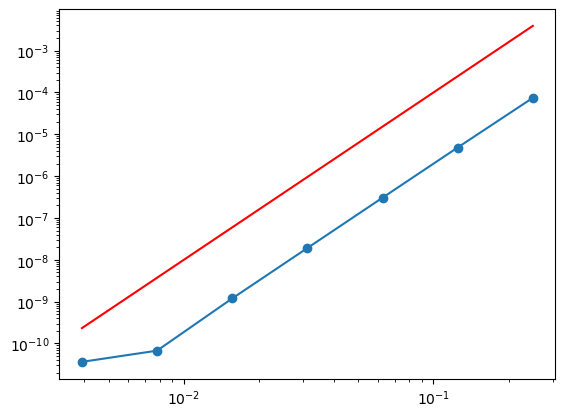

In [9]:
# Error loglog plots
plt.loglog(1/MM,discrete_max_err,'o-')
#plt.loglog(MM,interpola_H1_err**(1/2),'bd-')
plt.loglog(1/MM,1/(MM**((degree+1))),'r')

In [10]:
print(MM)

[  4.   8.  16.  32.  64. 128. 256.]


In [11]:
def FEM1(omega, M, degree, n_qpoints, alpha, beta, gamma, rhs):
    # -alpha u'' + beta u' + gamma u = f,  constant coefficients
    N = M*degree + 1                      # number of degrees of freedom
    vertices = mesh(omega, M)             # M+1 element endpoints (fixed)

    q, w = quadrature(n_qpoints)
    lagrange_points = np.linspace(0, 1, degree+1)

    phi  = np.array([lagrange_basis(lagrange_points, i)(q) for i in range(degree+1)]).T
    dphi = np.array([lagrange_basis_derivative(lagrange_points, i)(q) for i in range(degree+1)]).T

    A = sp.lil_matrix((N, N))
    F = np.zeros(N)

    for i in range(M):
        J   = mapping_J(vertices, i)
        JxW = J * w

        diffusion  = np.einsum('qi,qj,q', dphi, dphi, JxW) / J**2   # int phi_i' phi_j'
        convection = np.einsum('qi,qj,q', phi,  dphi, JxW) / J      # int phi_i  phi_j'
        reaction   = np.einsum('qi,qj,q', phi,  phi,  JxW)          # int phi_i  phi_j
        ele_A = alpha*diffusion + beta*convection + gamma*reaction
        ele_F = np.einsum('qi,q,q', phi, rhs(mapping(vertices, i)(q)), JxW)

        j = i*degree
        m = j + degree + 1
        A[j:m, j:m] += ele_A
        F[j:m]      += ele_F

    return A, F

alpha, beta, gamma = 1.0, 1.0, 2.0          # any constants you like
rhs = lambda x: (alpha + gamma)*np.sin(x) + beta*np.cos(x)

In [12]:
omega = [0,np.pi]
sol = lambda x: np.sin(x)

# degree of FEM basis
degree = 4

# Number of quadrature points
n_qpoints = 2*degree-1

# Number of experiments
no_experiments = 7

# Initialize
MM = np.zeros(no_experiments)
discrete_max_err = np.zeros(no_experiments)

# Solution loop
for i in range(no_experiments):
  M = 2**(i+2)
  MM[i] = M
  N = M*degree+1

  # call function computing FEM system
  A, F = FEM1(omega, M, degree, n_qpoints, alpha, beta, gamma, rhs)

  # and apply boundary conditions
  apply_boundary_conditions(omega,A, F, sol)
  A=A.tocsr()
  # Solve the system
  Uh = sp.linalg.spsolve(A,F)

  # Compute exact solution
  x=np.linspace(omega[0],omega[1],N)
  U=sol(x)

  # Compute discrete max norm error
  discrete_max_err[i] = max(abs(U-Uh))

  # Compute H1 norm of I_h u - u_h


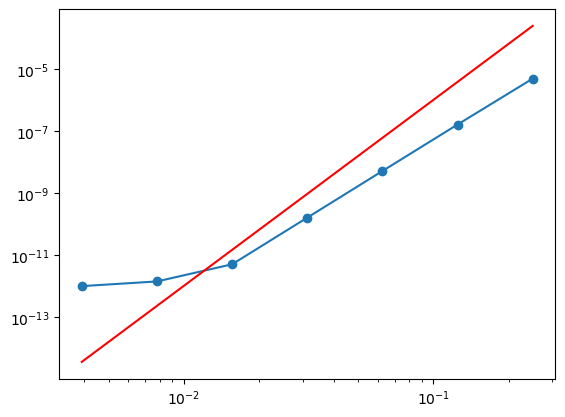

In [13]:
# Error loglog plots
plt.loglog(1/MM,discrete_max_err,'o-')
#plt.loglog(MM,interpola_H1_err**(1/2),'bd-')
plt.loglog(1/MM,1/(MM**((degree+1))),'r')

**Exercise 1**: Write function computing $H^1$-norm error and test convergence for $k>1$.

In [14]:
uexact=lambda x: np.sin(x)
du=lambda x: np.cos(x)
def H1_error(omega, M, degree, Uh, u, du, n_qpoints=8):
    vertices = mesh(omega, M)
    q, w = quadrature(n_qpoints)          # use many points: sin(x) is not a polynomial
    lagrange_points = np.linspace(0, 1, degree+1)

    phi  = np.array([lagrange_basis(lagrange_points, i)(q) for i in range(degree+1)]).T
    dphi = np.array([lagrange_basis_derivative(lagrange_points, i)(q) for i in range(degree+1)]).T

    err2 = 0.0
    for i in range(M):
        J   = mapping_J(vertices, i)
        x   = mapping(vertices, i)(q)             # physical quadrature points
        Ul  = Uh[i*degree : i*degree + degree + 1] # local degrees of freedom

        uh  = phi  @ Ul                            # u_h at quadrature points
        duh = dphi @ Ul / J                        # u_h' (chain rule: divide by J)

        err2 += np.sum(((u(x) - uh)**2 + (du(x) - duh)**2) * J * w)

    return np.sqrt(err2)

In [15]:
omega = [0,np.pi]
sol = lambda x: np.sin(x)

# degree of FEM basis
degree = 4

# Number of quadrature points
n_qpoints = 2*degree-1

# Number of experiments
no_experiments = 7

# Initialize
MM = np.zeros(no_experiments)
discrete_max_err = np.zeros(no_experiments)

# Solution loop
for i in range(no_experiments):
  M = 2**(i+2)
  MM[i] = M
  N = M*degree+1

  # call function computing FEM system
  A, F = FEM1(omega, M, degree, n_qpoints, alpha, beta, gamma, rhs)

  # and apply boundary conditions
  apply_boundary_conditions(omega,A, F, sol)
  A=A.tocsr()
  # Solve the system
  Uh = sp.linalg.spsolve(A,F)

  # Compute exact solution
  x=np.linspace(omega[0],omega[1],N)
  u=sol(x)

  # Compute discrete max norm error
  discrete_max_err[i] = H1_error(omega, M, degree, Uh, uexact, du, n_qpoints=8)

  # Compute H1 norm of I_h u - u_h


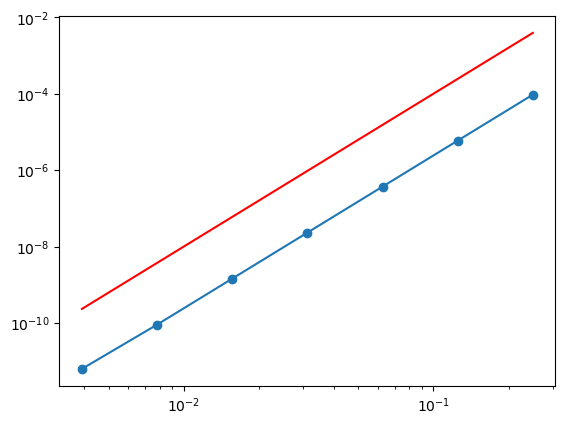

In [18]:
# Error loglog plots
plt.loglog(1/MM,discrete_max_err,'o-')
#plt.loglog(MM,interpola_H1_err**(1/2),'bd-')
plt.loglog(1/MM,1/(MM**((degree))),'r')

Excersis 2: write the code for the finite element method when the coefficients are not constant